In [1]:
import json, os, sys, time, warnings, logging, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset, Subset

from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, accuracy_score, brier_score_loss,
    precision_recall_curve, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve,
)
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.pipeline import Pipeline

In [2]:
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)
sns.set_style("whitegrid")

In [3]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

BASE_DIR = Path.cwd()
PATHS = {
    "processed": BASE_DIR / "dataset_processed.csv",
    "splits": BASE_DIR / "split_indices.npz",
    "cv_folds": BASE_DIR / "cv_fold_indices.npz",
    "artifact": BASE_DIR / "model_artifact.json",
    "models_dir": BASE_DIR / "models",
    "scaler": BASE_DIR / "scaler.pkl",
    "plots_dir": BASE_DIR / "plots",
}
PATHS["plots_dir"].mkdir(exist_ok=True)
PATHS["models_dir"].mkdir(parents=True, exist_ok=True)
(PATHS["models_dir"] / "reports").mkdir(exist_ok=True)
(PATHS["models_dir"] / "errors").mkdir(exist_ok=True)
(PATHS["models_dir"] / "cv_deep").mkdir(exist_ok=True)

# Experiment constants
TARGET_FPR = 1e-3
MAX_LEN = 75
BATCH_SIZE_DEEP = 512
NUM_WORKERS = 0  # Windows-safe
PIN_MEMORY = True  # для GPU
MAX_EPOCHS_DEEP = 40
PATIENCE_DEEP = 4
N_CV_SPLITS = 5
N_LEGIT_GROUPS = 10

# Model name registries
PRETRAINED_MODEL_NAMES = ["LightGBM", "XGBoost", "MLP"]
SCALED_MODEL_NAMES  = {"MLP"}


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  CUDA: {torch.version.cuda}")

Device: cuda
  GPU: NVIDIA GeForce RTX 2060
  CUDA: 12.6


In [4]:
def pick_threshold(y_val, y_prob, target_fpr=1e-3):
    """Порог, максимизирующий TPR при FPR <= target_fpr."""
    fpr, tpr, thr = roc_curve(y_val, y_prob)
    valid = fpr <= target_fpr
    if not valid.any():
        return 0.5, None, None
    idx = np.argmax(tpr * valid)
    return float(thr[idx]), float(fpr[idx]), float(tpr[idx])


def pick_threshold_at_recall(y_val, y_prob, target_recall=0.95):
    """Порог при достижении заданного recall."""
    _, r, thr = precision_recall_curve(y_val, y_prob)
    idx = np.searchsorted(-r, -target_recall, side="right") - 1
    return float(thr[max(idx, 0)])


def tpr_at_fpr(y_true, y_prob, target_fpr):
    """TPR при FPR <= target_fpr (threshold-free)."""
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    idx = np.searchsorted(fpr, target_fpr, side="right") - 1
    return float(tpr[max(idx, 0)])


def precision_at_recall(y_true, y_prob, target_recall):
    p, r, _ = precision_recall_curve(y_true, y_prob)
    idx = np.searchsorted(-r, -target_recall, side="right") - 1
    return float(p[max(idx, 0)])


def fp_per_million(fpr):
    return fpr * 1_000_000


def precision_at_prevalence(tpr, fpr, prevalence):
    num = prevalence * tpr
    den = num + (1 - prevalence) * fpr
    return num / den if den > 0 else 0.0


def metrics_block(y_true, y_prob, threshold):
    """17-колоночный блок метрик, как в models cell 9.1."""
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy":       accuracy_score(y_true, y_pred),
        "precision":      precision_score(y_true, y_pred, zero_division=0),
        "recall":         recall_score(y_true, y_pred, zero_division=0),
        "f1":             f1_score(y_true, y_pred, zero_division=0),
        "roc_auc":        roc_auc_score(y_true, y_prob),
        "pr_auc":         average_precision_score(y_true, y_prob),
        "tpr":            tp / (tp + fn) if tp + fn else 0.0,
        "fpr":            fp / (fp + tn) if fp + tn else 0.0,
        "fp_per_million": fp_per_million(fp / (fp + tn)) if fp + tn else 0.0,
        "brier":          brier_score_loss(y_true, y_prob),
    }


def per_family_recall(df_test, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    out = {}
    for fam in df_test.loc[df_test["label"] == 1, "class"].unique():
        m = (df_test["class"] == fam).to_numpy()
        out[fam] = float((y_pred[m] == 1).mean())
    return out


def top_errors(y_true, df, y_prob, threshold, n=10):
    """Возвращает (top_fp_df, top_fn_df) — как в models cell 12.1."""
    pred = (y_prob >= threshold).astype(int)
    fp_mask = (y_true == 0) & (pred == 1)
    fn_mask = (y_true == 1) & (pred == 0)
    fp = (
        df.loc[fp_mask, ["domain", "class"]]
          .assign(prob=y_prob[fp_mask])
          .sort_values("prob", ascending=False)
    )
    fn = (
        df.loc[fn_mask, ["domain", "class"]]
          .assign(prob=y_prob[fn_mask])
          .sort_values("prob", ascending=True)
    )
    return fp.head(n), fn.head(n)

In [5]:
full_df = pd.read_csv(PATHS["processed"])
splits = np.load(PATHS["splits"], allow_pickle=True)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]
test_id_idx = splits["test_id_idx"]
test_ood_idx = splits["test_ood_idx"]
held_families = splits["held_families"] if "held_families" in splits.files else None

with open(PATHS["artifact"], "r", encoding="utf-8") as f:
    artifact = json.load(f)

PRETRAINED_FEAT = artifact["feature_cols"]
PRETRAINED_THRESHOLDS = artifact["thresholds"]

feature_cols_final_all = [
    c for c in full_df.columns
    if c.startswith("nlp_") or c.startswith("isnan_")
]

print(f"full_df: {full_df.shape}")
print(f"PRETRAINED_FEAT: {len(PRETRAINED_FEAT)} features")
print(f"feature_cols_final_all: {len(feature_cols_final_all)} features")

dropped = set(feature_cols_final_all) - set(PRETRAINED_FEAT)
if dropped:
    print(f"  pruned in models: {sorted(dropped)}")

missing = set(PRETRAINED_FEAT) - set(feature_cols_final_all)
assert not missing, f"Features listed in artifact but missing in full_df: {missing}"

# Domains and labels
X_domain = full_df["domain"].values
y_all = full_df["label"].values.astype(np.int64)

# Test/val views
y_val = y_all[val_idx]
y_test_id = y_all[test_id_idx]
y_test_ood = y_all[test_ood_idx]
df_test_id = full_df.loc[test_id_idx].copy()
df_test_ood = full_df.loc[test_ood_idx].copy()

print(f"splits: train={len(train_idx)} val={len(val_idx)} "
      f"test_id={len(test_id_idx)} test_ood={len(test_ood_idx)}")
if held_families is not None:
    print(f"held_families: {list(held_families)}")

full_df: (1999920, 135)
PRETRAINED_FEAT: 130 features
feature_cols_final_all: 132 features
  pruned in models: ['nlp_2g_tske', 'nlp_3g_tske']
splits: train=1281254 val=274555 test_id=274555 test_ood=319547
held_families: [np.str_('fobber-v2'), np.str_('murofet-v1'), np.str_('cryptolocker'), np.str_('pykspa'), np.str_('shiotob'), np.str_('suppobox-1'), np.str_('tinba'), np.str_('simda'), np.str_('proslikefan'), np.str_('dircrypt')]


In [6]:
trained_models = {}
calibrators    = {}

for name in PRETRAINED_MODEL_NAMES:
    pkl_path = PATHS["models_dir"] / f"{name}.pkl"
    cal_path = PATHS["models_dir"] / f"{name}_cal.pkl"

    if not pkl_path.exists():
        print(f"Missing model: {pkl_path}")
        continue
    trained_models[name] = joblib.load(pkl_path)
    print(f"model: {name} ({type(trained_models[name]).__name__})")

    if cal_path.exists():
        calibrators[name] = joblib.load(cal_path)
        print(f"  calibrator: {name}")
    else:
        print(f"  missing calibrator: {cal_path}")

scaler = joblib.load(PATHS["scaler"])
print(f"\nscaler: {type(scaler).__name__} | n_features_in_={scaler.n_features_in_}")

model: LightGBM (LGBMClassifier)
  calibrator: LightGBM
model: XGBoost (XGBClassifier)
  calibrator: XGBoost
model: MLP (MLPClassifier)
  calibrator: MLP

scaler: StandardScaler | n_features_in_=130


In [7]:
feature_mismatches = []

for name, m in trained_models.items():
    # 1. LightGBM
    if hasattr(m, "feature_name_"):
        stored = list(m.feature_name_)
        if stored != PRETRAINED_FEAT:
            feature_mismatches.append({
                "model": name, "attr": "feature_name_",
                "expected_n": len(PRETRAINED_FEAT), "got_n": len(stored),
                "first_diff": next((i for i, (a, b) in enumerate(zip(stored, PRETRAINED_FEAT)) if a != b), None),
            })
    # 2. XGBoost
    elif hasattr(m, "get_booster"):
        stored = m.get_booster().feature_names
        if stored is not None and list(stored) != PRETRAINED_FEAT:
            feature_mismatches.append({
                "model": name, "attr": "booster.feature_names",
                "expected_n": len(PRETRAINED_FEAT), "got_n": len(stored),
                "first_diff": next((i for i, (a, b) in enumerate(zip(stored, PRETRAINED_FEAT)) if a != b), None),
            })
    elif hasattr(m, "n_features_in_"):
        if m.n_features_in_ != len(PRETRAINED_FEAT):
            feature_mismatches.append({
                "model": name, "attr": "n_features_in_",
                "expected_n": len(PRETRAINED_FEAT), "got_n": m.n_features_in_,
                "first_diff": None,
            })

if feature_mismatches:
    print("FEATURE MISMATCH DETECTED:")
    for item in feature_mismatches:
        print(f"  {item}")
    raise ValueError(
        "Models expect a different feature set than artifact['feature_cols']. "
        "Either artifact was regenerated or models were trained on a different feature_cols_final."
    )
print(f"All {len(trained_models)} models match PRETRAINED_FEAT ({len(PRETRAINED_FEAT)} features)")

All 3 models match PRETRAINED_FEAT (130 features)


In [8]:
def get_X_pretrained(name, X_raw):
    """Скейлит, если модель этого ждёт."""
    if name in SCALED_MODEL_NAMES:
        arr = scaler.transform(X_raw).astype("float32")
        return pd.DataFrame(arr, columns=X_raw.columns, index=X_raw.index)
    return X_raw

smoke_n = 1000
rng = np.random.RandomState(SEED)
smoke_pos = rng.choice(len(test_id_idx), size=smoke_n, replace=False)

X_smoke_raw = full_df.iloc[test_id_idx[smoke_pos]][PRETRAINED_FEAT].astype("float32")
y_smoke     = y_all[test_id_idx[smoke_pos]]

print(f"Smoke test on {smoke_n} rows from test_id (SEED={SEED}):\n")
print(f"{'model':15s} | {'AP':>7s} | {'mean_prob':>10s} | {'threshold':>10s}")
print("-" * 55)
for name, m in trained_models.items():
    X_in = get_X_pretrained(name, X_smoke_raw)
    p = m.predict_proba(X_in)
    p = p[:, 1] if p.ndim == 2 else p
    ap = average_precision_score(y_smoke, p)
    thr = PRETRAINED_THRESHOLDS.get(name, None)
    thr_str = f"{thr:.4f}" if thr is not None else "N/A"
    print(f"{name:15s} | {ap:.4f} | {p.mean():>10.4f} | {thr_str:>10s}")

Smoke test on 1000 rows from test_id (SEED=42):

model           |      AP |  mean_prob |  threshold
-------------------------------------------------------
LightGBM        | 0.9875 |     0.4633 |     0.9703
XGBoost         | 0.9863 |     0.4634 |     0.9725
MLP             | 0.9834 |     0.4582 |     0.9769


In [9]:
def get_features_for_idx(name, idx):
    """Ленивая загрузка: только нужные строки + правильный preprocessing для name."""
    X_raw = full_df.iloc[idx][PRETRAINED_FEAT].astype("float32")
    return get_X_pretrained(name, X_raw)

In [10]:
cv_idx = np.concatenate([train_idx, val_idx, test_id_idx])

# g_cv: DGA = class, legit = pseudo-groups via hash
g_cv = full_df.loc[cv_idx, "class"].values.astype(object).copy()
domain_cv = full_df.loc[cv_idx, "domain"].values
legit_mask = (g_cv == "legit")
legit_hashes = pd.util.hash_array(domain_cv[legit_mask]) % N_LEGIT_GROUPS
g_cv[legit_mask] = np.array([f"legit_{h}" for h in legit_hashes])

for g in np.unique(g_cv):
    classes = np.unique(y_all[cv_idx][g_cv == g])
    assert len(classes) == 1, f"Group {g} has mixed classes {classes}"

n_groups = len(np.unique(g_cv))
n_dga_groups = sum(not str(g).startswith("legit_") for g in np.unique(g_cv))
print(f"CV groups: {n_groups} total = {N_LEGIT_GROUPS} legit pseudo + {n_dga_groups} DGA families")

gkf = GroupKFold(n_splits=N_CV_SPLITS)
folds_pos = list(gkf.split(cv_idx, y_all[cv_idx], g_cv))  # позиции в cv_idx
folds_full = [(cv_idx[tr], cv_idx[va]) for tr, va in folds_pos]  # индексы в full_df

if PATHS["cv_folds"].exists():
    saved = np.load(PATHS["cv_folds"], allow_pickle=True)
    same = True
    for k, (tr, va) in enumerate(folds_full):
        if not np.array_equal(saved[f"fold_{k}_train"], tr): same = False; break
        if not np.array_equal(saved[f"fold_{k}_val"],   va): same = False; break
    if same:
        print(f"loaded existing {PATHS['cv_folds'].name} — matches reconstruction")
    else:
        raise ValueError(
            f"cv_fold_indices.npz does not match reconstruction. "
            f"Investigate: either delete {PATHS['cv_folds']} (will regenerate) "
            f"or check that split_indices.npz hasn't changed."
        )
else:
    save_dict = {
        "cv_idx":       cv_idx,
        "group_names":  np.array(np.unique(g_cv)),
        "n_legit_groups": np.int64(N_LEGIT_GROUPS),
        "n_splits":     np.int64(N_CV_SPLITS),
        "pandas_version":  np.array(pd.__version__),
        "python_version":  np.array(sys.version.split()[0]),
        "seed":         np.int64(SEED),
    }
    for k, (tr, va) in enumerate(folds_full):
        save_dict[f"fold_{k}_train"] = tr
        save_dict[f"fold_{k}_val"]   = va
    np.savez(PATHS["cv_folds"], **save_dict)
    print(f"saved {PATHS['cv_folds'].name}")

print("\nFold sizes (val only):")
for k, (tr, va) in enumerate(folds_full):
    g_va = full_df.loc[va, "class"].values
    n_legit = int(sum(1 for g in g_va if g == "legit"))
    n_dga   = len(va) - n_legit
    print(f"  fold {k}: val={len(va):>7d} (legit={n_legit:>6d}, dga={n_dga:>7d})")

CV groups: 50 total = 10 legit pseudo + 40 DGA families
loaded existing cv_fold_indices.npz — matches reconstruction

Fold sizes (val only):
  fold 0: val= 360062 (legit=200069, dga= 159993)
  fold 1: val= 369612 (legit=200060, dga= 169552)
  fold 2: val= 369985 (legit=199992, dga= 169993)
  fold 3: val= 365781 (legit=199893, dga= 165888)
  fold 4: val= 364924 (legit=199924, dga= 165000)


In [11]:
VOCAB = {chr(i): i + 1 for i in range(128)}
VOCAB["<PAD>"] = 0
VOCAB["<UNK>"] = 129

def encode_domain(domain, max_len=MAX_LEN):
    seq = [VOCAB.get(c, VOCAB["<UNK>"]) for c in domain.lower()[:max_len]]
    seq += [VOCAB["<PAD>"]] * (max_len - len(seq))
    return np.array(seq)

print("Encoding domains ONCE...")
X_train_enc    = np.array([encode_domain(d) for d in X_domain[train_idx]],    dtype=np.int64)
X_val_enc      = np.array([encode_domain(d) for d in X_domain[val_idx]],      dtype=np.int64)
X_test_id_enc  = np.array([encode_domain(d) for d in X_domain[test_id_idx]],  dtype=np.int64)
X_test_ood_enc = np.array([encode_domain(d) for d in X_domain[test_ood_idx]], dtype=np.int64)

X_train_enc    = torch.from_numpy(X_train_enc)
X_val_enc      = torch.from_numpy(X_val_enc)
X_test_id_enc  = torch.from_numpy(X_test_id_enc)
X_test_ood_enc = torch.from_numpy(X_test_ood_enc)

y_train_t    = torch.from_numpy(y_all[train_idx]).float()
y_val_t      = torch.from_numpy(y_all[val_idx]).float()
y_test_id_t  = torch.from_numpy(y_all[test_id_idx]).float()
y_test_ood_t = torch.from_numpy(y_all[test_ood_idx]).float()

class PreEncodedDataset(Dataset):
    def __init__(self, X_enc, y):
        self.X, self.y = X_enc, y
    def __len__(self): return len(self.X)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]

print(f"Train shape: {X_train_enc.shape}")
print(f"Test tensors: y_test_id_t={tuple(y_test_id_t.shape)}, y_test_ood_t={tuple(y_test_ood_t.shape)}")

Encoding domains ONCE...
Train shape: torch.Size([1281254, 75])
Test tensors: y_test_id_t=(274555,), y_test_ood_t=(319547,)


In [12]:
train_ds = PreEncodedDataset(X_train_enc, y_train_t)
val_ds   = PreEncodedDataset(X_val_enc,   y_val_t)
print(f"train_ds: {len(train_ds)} | val_ds: {len(val_ds)}")

train_ds: 1281254 | val_ds: 274555


In [13]:
assert X_train_enc.shape[1] == MAX_LEN == 75, \
    f"Encoded length {X_train_enc.shape[1]} != MAX_LEN={MAX_LEN}."
assert X_train_enc.dtype == torch.int64, f"Expected int64, got {X_train_enc.dtype}"

n_pos_train = int(y_train_t.sum().item())
n_neg_train = len(y_train_t) - n_pos_train
POS_WEIGHT = n_neg_train / n_pos_train

print(f"encoding ready: MAX_LEN={MAX_LEN}, vocab={len(VOCAB)}")
print(f"  train: {tuple(X_train_enc.shape)} | val: {tuple(X_val_enc.shape)}")
print(f"  test_id: {tuple(X_test_id_enc.shape)} | test_ood: {tuple(X_test_ood_enc.shape)}")
print(f"  train pos: {n_pos_train} | neg: {n_neg_train} | pos_weight={POS_WEIGHT:.4f}")

encoding ready: MAX_LEN=75, vocab=130
  train: (1281254, 75) | val: (274555, 75)
  test_id: (274555, 75) | test_ood: (319547, 75)
  train pos: 581298 | neg: 699956 | pos_weight=1.2041


In [14]:
def save_deep_artifact(name, model, config, history, best_val_ap, train_time_s):
    torch.save(model.state_dict(), PATHS["models_dir"] / f"{name}.pt")
    meta = {
        "name": name,
        "arch_config": config,
        "n_params": sum(p.numel() for p in model.parameters()),
        "best_val_ap": float(best_val_ap),
        "train_time_s": float(train_time_s),
        "history": history,
        "training": {
            "max_epochs": MAX_EPOCHS_DEEP, "patience": PATIENCE_DEEP,
            "batch_size": BATCH_SIZE_DEEP, "max_len": MAX_LEN,
            "num_workers": NUM_WORKERS, "pin_memory": PIN_MEMORY,
            "criterion": "val_average_precision",
        },
    }
    with open(PATHS["models_dir"] / f"{name}_config.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2, default=float)
    print(f"saved {name}.pt + {name}_config.json")

In [15]:
def train_deep_model(
    model_name, model, train_ds, val_ds, y_val_np,
    epochs=MAX_EPOCHS_DEEP, patience=PATIENCE_DEEP,
    batch_size=BATCH_SIZE_DEEP, lr=1e-3, weight_decay=1e-4, grad_clip=5.0,
    pos_weight=None, verbose=True,
):
    """
    Обучает deep-модель. Критерий — Val AP (как в models.ipynb).
    train_ds / val_ds — любые Dataset с __getitem__ -> (x, y):
        PreEncodedDataset | Subset(PreEncodedDataset, idx) | ...
    best_state: deep-copy тензоров на CPU (фикс shallow-copy bug).
    Возвращает (model_with_best, best_val_ap, history).
    """
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

    model = model.to(DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    pw = torch.tensor([pos_weight], device=DEVICE, dtype=torch.float32) if pos_weight else None
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)

    best_ap, best_state, patience_counter = 0.0, None, 0
    history = {"epoch": [], "train_loss": [], "val_ap": [], "lr": []}

    for epoch in range(epochs):
        # train
        model.train()
        t0 = time.perf_counter()
        loss_sum, n_batches = 0.0, 0
        for x, y in train_loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x), y)
            loss.backward()
            if grad_clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()
            loss_sum += loss.item()
            n_batches += 1
        scheduler.step()

        # validation
        model.eval()
        val_logits = []
        with torch.no_grad():
            for x, _ in val_loader:
                x = x.to(DEVICE, non_blocking=True)
                val_logits.append(model(x).float().cpu())
        val_probs = torch.sigmoid(torch.cat(val_logits)).numpy()
        val_ap = average_precision_score(y_val_np, val_probs)

        train_loss = loss_sum / n_batches
        cur_lr = scheduler.get_last_lr()[0]
        for k, v in [("epoch", epoch + 1), ("train_loss", train_loss),
                     ("val_ap", val_ap), ("lr", cur_lr)]:
            history[k].append(v)

        if verbose:
            print(f"  epoch {epoch+1:2d} | train {train_loss:.4f} | "
                  f"val_ap {val_ap:.4f} | lr {cur_lr:.2e} | {time.perf_counter()-t0:.0f}s")

        # best_state — deep-copy тензоров
        if val_ap > best_ap + 1e-4:
            best_ap = val_ap
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                if verbose:
                    print(f"  ⏹ early stop at epoch {epoch+1} (patience={patience})")
                break

    model.load_state_dict(best_state)
    return model, best_ap, history

In [16]:
def predict_deep(model, X_enc_or_ds, batch_size=2048):
    """
    Инференс через DataLoader.
    X_enc_or_ds: torch.Tensor (int64) или Dataset с __getitem__ -> (x, *) или (x,)
    """
    model.eval()
    if isinstance(X_enc_or_ds, Dataset):
        ds = X_enc_or_ds
    else:
        ds = TensorDataset(X_enc_or_ds)  # обёртка: __getitem__ -> (x,)

    loader = DataLoader(ds, batch_size=batch_size, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

    probs = []
    with torch.no_grad():
        for batch in loader:
            x = (batch[0] if isinstance(batch, (list, tuple)) else batch).to(DEVICE, non_blocking=True)
            logits = model(x).float().cpu().numpy()
            probs.append(1.0 / (1.0 + np.exp(-logits)))
    return np.concatenate(probs)

In [17]:
def load_deep_model(name, model_class, config, device=DEVICE):
    """
    Загружает model_class(**config) из {name}.pt + {name}_config.json.
    Возвращает (model_on_device, hist, best_val_ap) или None, если артефактов нет.
    """
    state_path = PATHS["models_dir"] / f"{name}.pt"
    cfg_path   = PATHS["models_dir"] / f"{name}_config.json"
    if not (state_path.exists() and cfg_path.exists()):
        return None

    with open(cfg_path, encoding="utf-8") as f:
        meta = json.load(f)

    model = model_class(**config).to(device)
    model.load_state_dict(torch.load(state_path, map_location=device))

    hist = meta["history"]
    best_ap = max(hist["val_ap"])
    print(f"Loaded {name}  ({meta['n_params']:,d} params, "
          f"{hist['epoch'][-1]} epochs, val_ap={best_ap:.4f})\n")
    return model, hist, best_ap

In [30]:
def best_state_epoch(hist_val_ap, threshold=1e-4):
    """
    Воспроизводит логику выбора best_state из train_deep_model.
    Возвращает индекс (0-based) эпохи, где best_state был сохранён в последний раз.
    """
    best = 0.0
    idx = 0
    for i, v in enumerate(hist_val_ap):
        if v > best + threshold:
            best = v
            idx = i
    return idx

In [18]:
def release_gpu(model, name):
    """Отправляет модель на CPU + очищает CUDA-кэш. No-op если model is None."""
    if model is None:
        return None
    dev = next(model.parameters()).device
    if dev.type != "cpu":
        model = model.cpu()
        print(f"{name:20s}: {dev} → cpu")
    else:
        print(f"{name:20s}: already on cpu")
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    free = torch.cuda.mem_get_info()[0] / 1e9
    print(f"VRAM: {free:.2f} GB free")
    return model

In [19]:
class CharCNN(nn.Module):
    """
    Multi-kernel CharCNN с PAD-маскированием перед global max-pool.
    Свёртки с padding='same': длина = MAX_LEN, маска по исходным токенам.
    """
    def __init__(self, vocab_size=130, embed_dim=64,
                 kernel_sizes=(3, 5, 7), num_filters=128,
                 fc_hidden=(128,), dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.convs = nn.ModuleList([
            nn.Conv1d(embed_dim, num_filters, k, padding=k // 2) for k in kernel_sizes
        ])
        self.bns = nn.ModuleList([nn.BatchNorm1d(num_filters) for _ in kernel_sizes])

        n_concat = num_filters * len(kernel_sizes)
        layers, prev = [], n_concat
        for h in fc_hidden:
            layers += [nn.Linear(prev, h), nn.GELU(), nn.Dropout(dropout)]
            prev = h
        layers += [nn.Linear(prev, 1)]
        self.head = nn.Sequential(*layers)

    def forward(self, x_long):
        mask = (x_long != 0)                               # (B, L)
        x = self.embedding(x_long).permute(0, 2, 1)        # (B, E, L)
        outs = []
        for conv, bn in zip(self.convs, self.bns):
            y = torch.relu(bn(conv(x)))                    # (B, F, L)
            y = y.masked_fill(~mask.unsqueeze(1), float('-inf'))
            outs.append(y.max(dim=-1).values)              # (B, F)
        x = torch.cat(outs, dim=1)
        x = torch.where(torch.isinf(x), torch.zeros_like(x), x)
        return self.head(x).squeeze(-1)


CHARC_NN_CONFIGS = {
    "CharCNN-Small":  dict(embed_dim=64,  kernel_sizes=(3, 5, 7), num_filters=128,
                           fc_hidden=(128,),       dropout=0.3),
    "CharCNN-Medium": dict(embed_dim=128, kernel_sizes=(3, 5, 7), num_filters=320,
                           fc_hidden=(512, 256),   dropout=0.3),
}

for name, cfg in CHARC_NN_CONFIGS.items():
    m = CharCNN(**cfg)
    print(f"{name:18s} | params={sum(p.numel() for p in m.parameters()):>9,d}")
    del m

CharCNN-Small      | params=  181,761
CharCNN-Medium     | params=1,257,537


In [20]:
NAME = "CharCNN-Small"
print(f"{'=' * 60}\n{NAME}\n{'=' * 60}")

loaded = load_deep_model(NAME, CharCNN, CHARC_NN_CONFIGS[NAME])
if loaded is not None:
    char_cnn_small, hist_schar, ap_schar = loaded
else:
    char_cnn_small = CharCNN(**CHARC_NN_CONFIGS[NAME])
    print(f"params: {sum(p.numel() for p in char_cnn_small.parameters()):,d}")
    t0 = time.perf_counter()
    char_cnn_small, ap_schar, hist_schar = train_deep_model(
        NAME, char_cnn_small, train_ds, val_ds, 
        y_val_np=y_val, pos_weight=POS_WEIGHT,
    )
    train_time_cs = time.perf_counter() - t0
    save_deep_artifact(NAME,  char_cnn_small,  
                       CHARC_NN_CONFIGS[NAME],
                       hist_schar,  ap_schar,  train_time_cs)
    print(f"\ndone in {train_time_cs/60:.1f} min | best val_ap={ap_schar:.4f}\n")

assert ap_schar > 0.99, f"{NAME}: val_ap={ap_schar:.4f} — below threshold"

p_val_schar     = predict_deep(char_cnn_small, X_val_enc)
p_test_id_schar = predict_deep(char_cnn_small, X_test_id_enc)
p_ood_schar     = predict_deep(char_cnn_small, X_test_ood_enc)

char_cnn_small = release_gpu(char_cnn_small, "char_cnn_small")


CharCNN-Small
Loaded CharCNN-Small  (181,761 params, 17 epochs, val_ap=0.9967)

char_cnn_small      : cuda:0 → cpu
VRAM: 5.32 GB free


In [21]:
NAME = "CharCNN-Medium"
print(f"{'=' * 60}\n{NAME}\n{'=' * 60}")

loaded = load_deep_model(NAME, CharCNN, CHARC_NN_CONFIGS[NAME])
if loaded is not None:
    char_cnn_medium, hist_mchar, ap_mchar = loaded
else:
    char_cnn_medium = CharCNN(**CHARC_NN_CONFIGS[NAME])
    print(f"params: {sum(p.numel() for p in char_cnn_medium.parameters()):,d}")
    t0 = time.perf_counter()
    char_cnn_medium, ap_mchar, hist_mchar = train_deep_model(
        NAME, char_cnn_medium,
        train_ds, val_ds, y_val_np=y_val,
        pos_weight=POS_WEIGHT,
    )
    train_time_mchar = time.perf_counter() - t0
    save_deep_artifact(NAME, char_cnn_medium, CHARC_NN_CONFIGS[NAME],
                       hist_mchar, ap_mchar, train_time_mchar)
    print(f"\ndone in {train_time_mchar/60:.1f} min | best val_ap={ap_mchar:.4f}\n")

assert ap_mchar > 0.99, f"{NAME}: val_ap={ap_mchar:.4f} — below threshold"

p_val_mchar     = predict_deep(char_cnn_medium, X_val_enc)
p_test_id_mchar = predict_deep(char_cnn_medium, X_test_id_enc)
p_ood_mchar     = predict_deep(char_cnn_medium, X_test_ood_enc)

char_cnn_medium = release_gpu(char_cnn_medium, "char_cnn_medium")

CharCNN-Medium
Loaded CharCNN-Medium  (1,257,537 params, 13 epochs, val_ap=0.9978)

char_cnn_medium     : cuda:0 → cpu
VRAM: 5.32 GB free


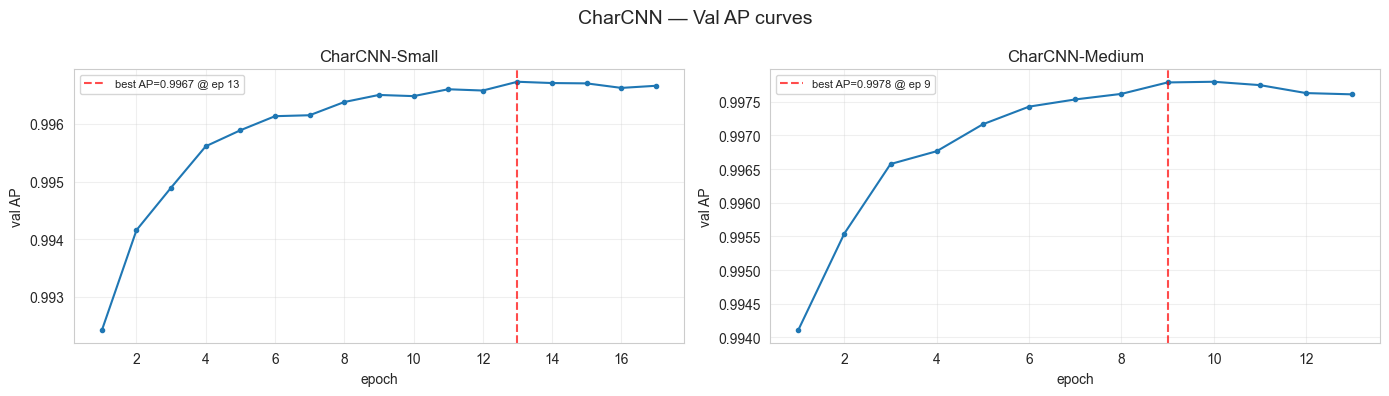

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, hist) in zip(axes, [("CharCNN-Small", hist_schar),
                                    ("CharCNN-Medium", hist_mchar)]):
    ap = hist["val_ap"]; best_i = best_state_epoch(hist["val_ap"])
    ax.plot(hist["epoch"], ap, marker="o", markersize=3, linewidth=1.5)
    ax.axvline(hist["epoch"][best_i], color="r", ls="--", alpha=0.7,
               label=f"best AP={ap[best_i]:.4f} @ ep {hist['epoch'][best_i]}")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("val AP")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle("CharCNN — Val AP curves", fontsize=14)
plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/charcnn_val_ap.png", dpi=140)
plt.show()

In [23]:
class CharBERT(nn.Module):
    """
    Char-level Transformer с CLS-токеном и learnable positional encoding.

    - Pre-LN (norm_first=True) — стабильнее при from-scratch обучении.
    - Padding mask через src_key_padding_mask: CLS никогда не pad.
    - Attention доступен через hooks на encoder.layers[i].self_attn (шаг 8).
    """
    def __init__(
        self,
        vocab_size=130,
        d_model=64,
        nhead=4,
        num_layers=4,
        dim_feedforward=256,
        dropout=0.1,
        max_len=75,
    ):
        super().__init__()
        self.d_model = d_model
        self.max_len = max_len

        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        # +1 позиция под CLS
        self.pos_embedding = nn.Parameter(torch.zeros(1, max_len + 1, d_model))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, activation="gelu",
            batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 1)

        self._init_weights()

    def _init_weights(self):
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)
        nn.init.normal_(self.embedding.weight, std=0.02)
        with torch.no_grad():
            self.embedding.weight[0].fill_(0.0)   # PAD остаётся нулевым
        nn.init.xavier_uniform_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x_long):
        # x_long: (B, L) int64, 0 = pad
        B, L = x_long.shape

        x = self.embedding(x_long)                              # (B, L, D)

        # CLS prepend
        cls = self.cls_token.expand(B, -1, -1)                  # (B, 1, D)
        x = torch.cat([cls, x], dim=1)                          # (B, L+1, D)
        x = x + self.pos_embedding[:, :L + 1, :]

        # Padding mask: True = ignore
        mask_pad = (x_long == 0)                                # (B, L)
        cls_mask = torch.zeros(B, 1, dtype=torch.bool, device=x_long.device)
        src_key_padding_mask = torch.cat([cls_mask, mask_pad], dim=1)

        encoded = self.encoder(x, src_key_padding_mask=src_key_padding_mask)
        cls_out = self.norm(encoded[:, 0, :])
        return self.head(cls_out).squeeze(-1)


CHARBERT_CONFIGS = {
    "CharBERT-Small": dict(
        d_model=64,  nhead=4, num_layers=4, dim_feedforward=256,
        dropout=0.1, max_len=MAX_LEN,
    ),
    "CharBERT-Medium": dict(
        d_model=128, nhead=4, num_layers=6, dim_feedforward=512,
        dropout=0.1, max_len=MAX_LEN,
    ),
}

for name, cfg in CHARBERT_CONFIGS.items():
    m = CharBERT(**cfg)
    n = sum(p.numel() for p in m.parameters())
    print(f"{name:18s} | params={n:>9,d}")
    del m

CharBERT-Small     | params=  213,377
CharBERT-Medium    | params=1,216,513


In [24]:
NAME = "CharBERT-Small"
print(f"{'=' * 60}\n{NAME}\n{'=' * 60}")

loaded = load_deep_model(NAME, CharBERT, CHARBERT_CONFIGS[NAME])
if loaded is not None:
    charbert_small, hist_sbert, ap_sbert = loaded
else:
    charbert_small = CharBERT(**CHARBERT_CONFIGS[NAME])
    print(f"params: {sum(p.numel() for p in charbert_small.parameters()):,d}")
    t0 = time.perf_counter()
    charbert_small, ap_sbert, hist_sbert = train_deep_model(
        NAME, charbert_small,
        train_ds, val_ds, y_val_np=y_val,
        batch_size=512, lr=1e-3, weight_decay=0.01,
        pos_weight=POS_WEIGHT,
    )
    train_time_sbert = time.perf_counter() - t0
    save_deep_artifact(NAME,  charbert_small,  CHARBERT_CONFIGS[NAME],
                       hist_sbert,  ap_sbert,  train_time_sbert)
    print(f"\ndone in {train_time_sbert/60:.1f} min | best val_ap={ap_sbert:.4f}\n")

assert ap_sbert > 0.99, f"{NAME}: val_ap={ap_sbert:.4f} — below threshold"

p_val_sbert     = predict_deep(charbert_small, X_val_enc,       batch_size=512)
p_test_id_sbert = predict_deep(charbert_small, X_test_id_enc,   batch_size=512)
p_ood_sbert     = predict_deep(charbert_small, X_test_ood_enc,  batch_size=512)

charbert_small = release_gpu(charbert_small, "charbert_small")

CharBERT-Small
Loaded CharBERT-Small  (213,377 params, 36 epochs, val_ap=0.9973)

charbert_small      : cuda:0 → cpu
VRAM: 5.32 GB free


In [25]:
NAME = "CharBERT-Medium"
print(f"{'=' * 60}\n{NAME}\n{'=' * 60}")

loaded = load_deep_model(NAME, CharBERT, CHARBERT_CONFIGS[NAME])
if loaded is not None:
    charbert_medium, hist_mbert, ap_mbert = loaded
else:
    charbert_medium = CharBERT(**CHARBERT_CONFIGS[NAME])
    print(f"params: {sum(p.numel() for p in charbert_medium.parameters()):,d}")
    t0 = time.perf_counter()
    charbert_medium, ap_mbert, hist_mbert = train_deep_model(
        NAME, charbert_medium,
        train_ds, val_ds, y_val_np=y_val,
        batch_size=512, lr=1e-3, weight_decay=0.01,
        pos_weight=POS_WEIGHT,
    )
    train_time_mbert = time.perf_counter() - t0
    save_deep_artifact(NAME,  charbert_medium,  CHARBERT_CONFIGS[NAME],
                       hist_mbert,  ap_mbert,  train_time_mbert)
    print(f"\ndone in {train_time_mbert/60:.1f} min | best val_ap={ap_mbert:.4f}\n")

assert ap_mbert > 0.99, f"{NAME}: val_ap={ap_mbert:.4f} — below threshold"

p_val_mbert     = predict_deep(charbert_medium, X_val_enc,       batch_size=512)
p_test_id_mbert = predict_deep(charbert_medium, X_test_id_enc,   batch_size=512)
p_ood_mbert     = predict_deep(charbert_medium, X_test_ood_enc,  batch_size=512)

charbert_medium = release_gpu(charbert_medium, "charbert_medium")

CharBERT-Medium
params: 1,216,513
  epoch  1 | train 0.2283 | val_ap 0.9842 | lr 9.98e-04 | 487s
  epoch  2 | train 0.1682 | val_ap 0.9877 | lr 9.94e-04 | 487s
  epoch  3 | train 0.1533 | val_ap 0.9895 | lr 9.86e-04 | 489s
  epoch  4 | train 0.1423 | val_ap 0.9904 | lr 9.76e-04 | 490s
  epoch  5 | train 0.1336 | val_ap 0.9910 | lr 9.62e-04 | 489s
  epoch  6 | train 0.1263 | val_ap 0.9922 | lr 9.46e-04 | 489s
  epoch  7 | train 0.1214 | val_ap 0.9931 | lr 9.26e-04 | 489s
  epoch  8 | train 0.1160 | val_ap 0.9936 | lr 9.05e-04 | 489s
  epoch  9 | train 0.1121 | val_ap 0.9940 | lr 8.80e-04 | 489s
  epoch 10 | train 0.1081 | val_ap 0.9945 | lr 8.54e-04 | 489s
  epoch 11 | train 0.1039 | val_ap 0.9947 | lr 8.25e-04 | 489s
  epoch 12 | train 0.1005 | val_ap 0.9951 | lr 7.94e-04 | 488s
  epoch 13 | train 0.0975 | val_ap 0.9956 | lr 7.61e-04 | 488s
  epoch 14 | train 0.0941 | val_ap 0.9958 | lr 7.27e-04 | 489s
  epoch 15 | train 0.0911 | val_ap 0.9959 | lr 6.91e-04 | 489s
  epoch 16 | train 0.

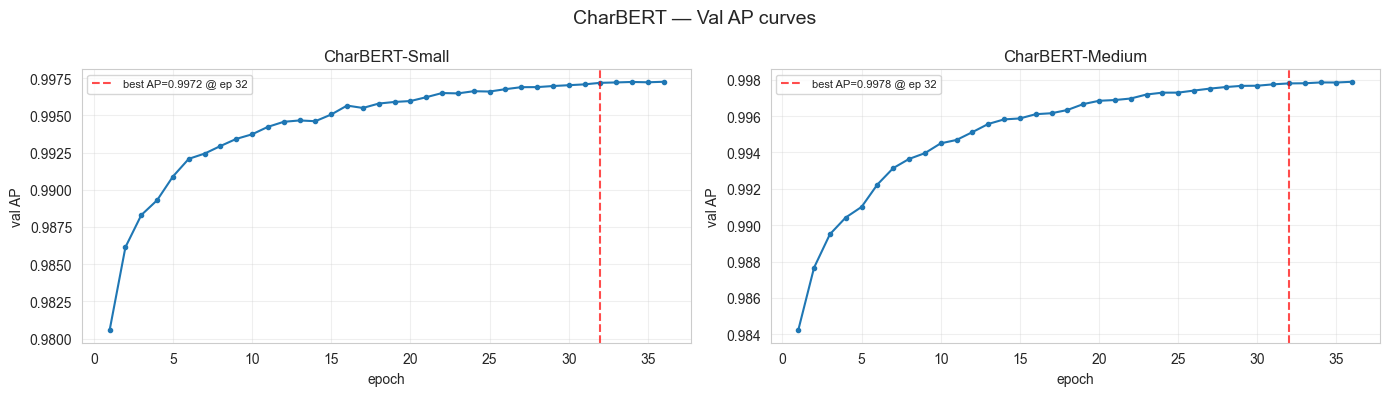

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, hist) in zip(axes, [("CharBERT-Small", hist_sbert),
                                    ("CharBERT-Medium", hist_mbert)]):
    ap = hist["val_ap"]; best_i = best_state_epoch(hist["val_ap"])
    ax.plot(hist["epoch"], ap, marker="o", markersize=3, linewidth=1.5)
    ax.axvline(hist["epoch"][best_i], color="r", ls="--", alpha=0.7,
               label=f"best AP={ap[best_i]:.4f} @ ep {hist['epoch'][best_i]}")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("val AP")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle("CharBERT — Val AP curves", fontsize=14)
plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/chatbert_val_ap.png", dpi=140)
plt.show()

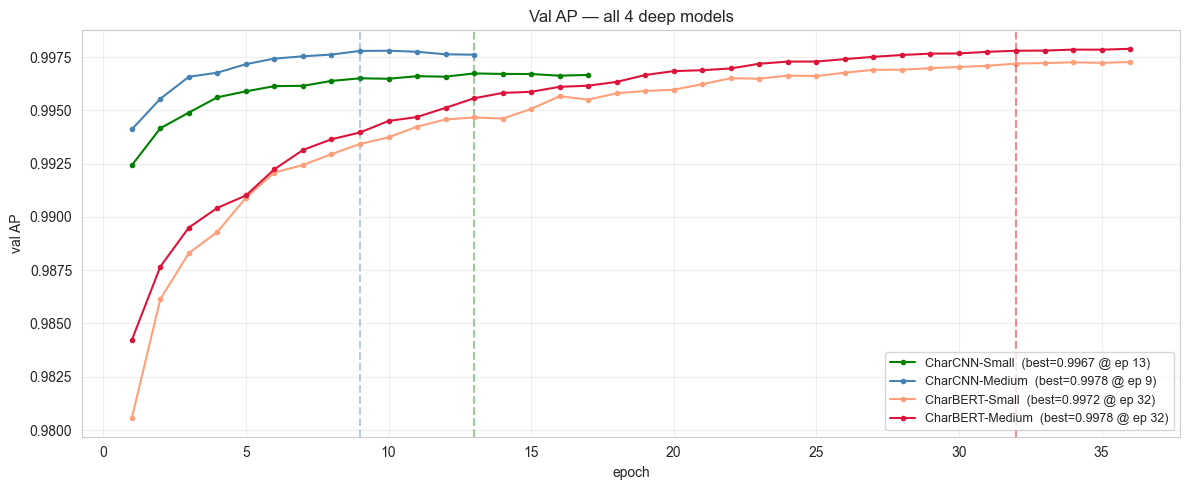

In [33]:
all_hist = {
    "CharCNN-Small":   hist_schar,
    "CharCNN-Medium":  hist_mchar,
    "CharBERT-Small":  hist_sbert,
    "CharBERT-Medium": hist_mbert,
}
colors = {
    "CharCNN-Small":   "green",
    "CharCNN-Medium":  "steelblue",
    "CharBERT-Small":  "lightsalmon",
    "CharBERT-Medium": "crimson",
}

fig, ax = plt.subplots(figsize=(12, 5))
for name, hist in all_hist.items():
    ap = hist["val_ap"]; best_i = best_state_epoch(hist["val_ap"])
    ax.plot(hist["epoch"], ap, marker="o", markersize=3, linewidth=1.5,
            color=colors[name],
            label=f"{name}  (best={ap[best_i]:.4f} @ ep {hist['epoch'][best_i]})")
    ax.axvline(hist["epoch"][best_i], color=colors[name], ls="--", alpha=0.4)

ax.set_title("Val AP — all 4 deep models")
ax.set_xlabel("epoch")
ax.set_ylabel("val AP")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/deep_val_ap_all4.png", dpi=140)
plt.show()